# Distinguishing causal variable roles

A variable's causal role is defined relative to a graph, a treatment, and an outcome:

$$
r_G(Z;X,Y)\in\{\operatorname{confounder},\operatorname{mediator},\operatorname{collider},\operatorname{instrument},\operatorname{ancestor},\operatorname{descendant},\operatorname{independent}\}.
$$

Here, $G$ is a directed acyclic graph, $X$ is the treatment, $Y$ is the outcome, $Z$ is the variable being classified, and $r_G(Z;X,Y)$ is its role for this particular treatment-outcome question.

## Notebook setup

### Number formatting for tables

In [ ]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered




### Table display and number formatting

In [ ]:
def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)



### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

from pathlib import Path
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

FIGURES = ROOT / "outputs" / "figures" / "01_causal_roles"
TABLES = ROOT / "outputs" / "tables" / "01_causal_roles"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]});



In [ ]:
def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display_notebook_figure(figure)
    plt.close(figure)



## Draw directed graph

In [ ]:
def draw_directed_graph(axis, graph, positions, title, colors=None, labels=None, edge_styles=None, node_size=1250, font_size=9):
    node_colors = [palette["cyan"] if colors is None else colors.get(node, palette["cyan"]) for node in graph.nodes]
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=node_colors, node_size=node_size, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, labels=labels, font_color=palette["background"], font_weight="bold", font_size=font_size)
    if edge_styles is None:
        nx.draw_networkx_edges(graph, positions, ax=axis, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    else:
        for edge in graph.edges:
            style = edge_styles.get(edge, "solid")
            nx.draw_networkx_edges(graph, positions, ax=axis, edgelist=[edge], edge_color=palette["text"], width=1.8, style=style, arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    axis.set_title(title)
    axis.set_axis_off()

def partial_correlation(x, y, controls=None):
    x_values = np.asarray(x, dtype=float).reshape(-1)
    y_values = np.asarray(y, dtype=float).reshape(-1)
    if controls is None or np.asarray(controls).size == 0:
        return float(np.corrcoef(x_values, y_values)[0, 1])
    control_values = np.asarray(controls, dtype=float)
    if control_values.ndim == 1:
        control_values = control_values.reshape(-1, 1)
    design = np.column_stack([np.ones(len(control_values)), control_values])
    x_residual = x_values - design @ np.linalg.lstsq(design, x_values, rcond=None)[0]
    y_residual = y_values - design @ np.linalg.lstsq(design, y_values, rcond=None)[0]
    return float(np.corrcoef(x_residual, y_residual)[0, 1])



## Regression summary

In [ ]:
def regression_summary(frame, outcome, treatment, controls):
    columns = [treatment] + list(controls)
    design = np.column_stack([np.ones(len(frame)), frame[columns].to_numpy(dtype=float)])
    response = frame[outcome].to_numpy(dtype=float)
    coefficients = np.linalg.lstsq(design, response, rcond=None)[0]
    fitted = design @ coefficients
    residual = response - fitted
    total = response - response.mean()
    r_squared = 1.0 - float(residual @ residual) / float(total @ total)
    return float(coefficients[1]), r_squared

def path_is_active(graph, path, conditioned):
    conditioned_set = set(conditioned)
    collider_openers = set(conditioned_set)
    for node in conditioned_set:
        collider_openers.update(nx.ancestors(graph, node))
    for index in range(1, len(path) - 1):
        previous_node = path[index - 1]
        middle_node = path[index]
        next_node = path[index + 1]
        collider = graph.has_edge(previous_node, middle_node) and graph.has_edge(next_node, middle_node)
        if collider and middle_node not in collider_openers:
            return False
        if not collider and middle_node in conditioned_set:
            return False
    return True



## Path records

In [ ]:
def path_records(graph, source, target, conditioned):
    records = []
    paths = list(nx.all_simple_paths(graph.to_undirected(), source=source, target=target))
    for path in paths:
        colliders = []
        for index in range(1, len(path) - 1):
            previous_node = path[index - 1]
            middle_node = path[index]
            next_node = path[index + 1]
            if graph.has_edge(previous_node, middle_node) and graph.has_edge(next_node, middle_node):
                colliders.append(middle_node)
        records.append({"Path": " - ".join(path), "Conditioning set": ", ".join(sorted(conditioned)) if conditioned else "None", "Collider nodes": ", ".join(colliders) if colliders else "None", "Active": path_is_active(graph, path, conditioned)})
    return records

def fit_sem_covariance(covariance, graph, nodes):
    covariance_values = np.asarray(covariance, dtype=float)
    node_index = {node: index for index, node in enumerate(nodes)}
    coefficients = np.zeros_like(covariance_values)
    residual_variances = np.zeros(len(nodes), dtype=float)
    for node in nodes:
        row = node_index[node]
        parents = list(graph.predecessors(node))
        if parents:
            parent_indices = [node_index[parent] for parent in parents]
            beta = covariance_values[row, parent_indices] @ np.linalg.inv(covariance_values[np.ix_(parent_indices, parent_indices)])
            coefficients[row, parent_indices] = beta
            residual_variances[row] = covariance_values[row, row] - beta @ covariance_values[parent_indices, row]
        else:
            residual_variances[row] = covariance_values[row, row]
    transform = np.linalg.inv(np.eye(len(nodes)) - coefficients)
    implied = transform @ np.diag(residual_variances) @ transform.T
    return coefficients, residual_variances, implied



## Graph structure and path checks

In [ ]:
def role_color(role):
    mapping = {"confounder": palette["amber"], "mediator": palette["green"], "collider": palette["rose"], "instrument": palette["violet"], "ancestor_of_outcome": palette["cyan"], "descendant_of_outcome": palette["muted"], "descendant_of_treatment": palette["muted"], "independent": palette["grid"]}
    return mapping.get(role, palette["cyan"])

sys.path.insert(0, str(ROOT))
from causal_notebook_tools import classify_causal_role, is_collider, is_confounder, is_instrument, is_mediator

treatment = "HML"
outcome = "PC"
finance_graph = nx.DiGraph([
    ("HML", "OI"),
    ("OI", "PC"),
    ("MOM", "HML"),
    ("MOM", "PC"),
    ("OI", "BAS"),
    ("PC", "BAS"),
    ("IV", "HML"),
    ("AO", "PC"),
    ("PC", "DO"),
    ("HML", "DT"),
])
finance_graph.add_node("U")
expected_roles = {
    "MOM": "confounder",
    "OI": "mediator",
    "BAS": "collider",
    "IV": "instrument",
    "AO": "ancestor_of_outcome",
    "DO": "collider",
    "DT": "descendant_of_treatment",
    "U": "independent",
}


## Variable roles relative to HML and price change

,Variable,Expected role,Observed role,Matched
0,MOM,confounder,confounder,True
1,OI,mediator,mediator,True
2,BAS,collider,collider,True
3,IV,instrument,instrument,True
4,AO,ancestor of outcome,ancestor of outcome,True
5,DO,collider,collider,True
6,DT,descendant of treatment,descendant of treatment,True
7,U,independent,independent,True


,Variable,Confounder,Mediator,Collider,Instrument
0,MOM,True,False,False,False
1,OI,False,True,False,False
2,BAS,False,False,True,False
3,IV,False,False,False,True
4,AO,False,False,False,False
5,DO,False,False,True,False
6,DT,False,False,False,False
7,U,False,False,False,False


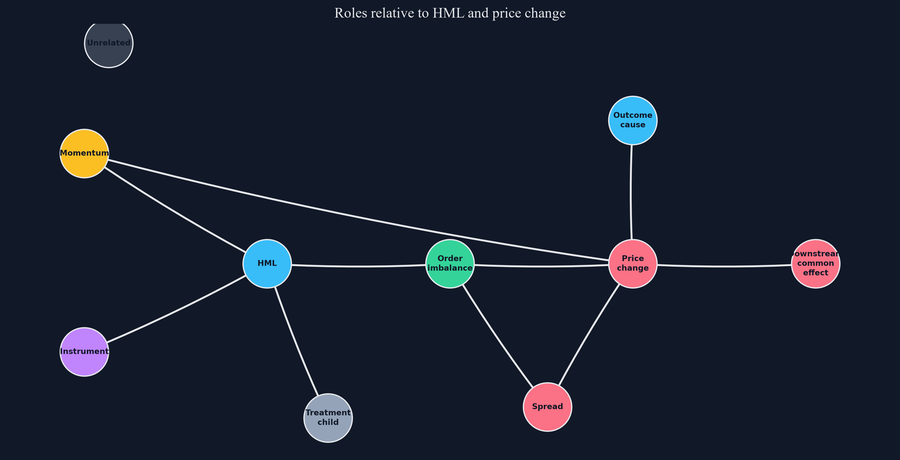

In [1]:
role_rows = []
for variable, expected in expected_roles.items():
    observed = classify_causal_role(finance_graph, treatment, outcome, variable)
    role_rows.append({"Variable": variable, "Expected role": expected.replace("_", " "), "Observed role": observed.replace("_", " "), "Matched": observed == expected})
role_classification = pd.DataFrame(role_rows)
finance_graph_edges = pd.DataFrame([{"From": source, "To": target} for source, target in finance_graph.edges])
role_boolean_checks = pd.DataFrame([
    {"Variable": variable, "Confounder": is_confounder(finance_graph, treatment, outcome, variable), "Mediator": is_mediator(finance_graph, treatment, outcome, variable), "Collider": is_collider(finance_graph, treatment, outcome, variable), "Instrument": is_instrument(finance_graph, treatment, outcome, variable)}
    for variable in expected_roles
])
save_table(finance_graph_edges, "finance_graph_edges", "Directed edges in the Chapter 23 finance graph.", "tab:chapter23-finance-edges")
save_table(role_classification, "role_classification", "Variable roles relative to HML and price change.", "tab:chapter23-role-classification")
save_table(role_boolean_checks, "role_boolean_checks", "Direct checks of the four central variable roles.", "tab:chapter23-role-booleans")
display(role_classification)
display(role_boolean_checks)

positions = {"MOM": (-2.0, 1.0), "IV": (-2.0, -0.8), "U": (-1.8, 2.0), "HML": (-0.5, 0.0), "OI": (1.0, 0.0), "PC": (2.5, 0.0), "BAS": (1.8, -1.3), "AO": (2.5, 1.3), "DO": (4.0, 0.0), "DT": (0.0, -1.4)}
node_colors = {treatment: palette["cyan"], outcome: palette["rose"]}
for variable, expected in expected_roles.items():
    node_colors[variable] = role_color(expected)
labels = {"HML": "HML", "OI": "Order\nimbalance", "PC": "Price\nchange", "MOM": "Momentum", "BAS": "Spread", "IV": "Instrument", "AO": "Outcome\ncause", "DO": "Downstream\ncommon\neffect", "DT": "Treatment\nchild", "U": "Unrelated"}
figure, axis = plt.subplots(figsize=(12, 6.2))
draw_directed_graph(axis, finance_graph, positions, "Roles relative to HML and price change", node_colors, labels, node_size=2100, font_size=7.5)
figure.tight_layout()
save_figure(figure, "finance_role_graph")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Ordering causal roles in a graph

Ancestor and descendant sets collect every node connected by a directed path into or out of a chosen node:

$$
\operatorname{An}_G(v)=\{u:u\rightsquigarrow v\},\qquad \operatorname{De}_G(v)=\{u:v\rightsquigarrow u\}.
$$

Here, $v$ is a chosen node, $u$ is another node, $u\rightsquigarrow v$ denotes a directed path from $u$ to $v$, $\operatorname{An}_G(v)$ is the ancestor set, and $\operatorname{De}_G(v)$ is the descendant set.

,Variable,Ancestor of treatment,Ancestor of outcome,Descendant of treatment,Descendant of outcome,Role
0,MOM,True,True,False,False,confounder
1,OI,False,True,True,False,mediator
2,BAS,False,False,True,True,collider
3,IV,True,True,False,False,instrument
4,AO,False,True,False,False,ancestor of outcome
5,DO,False,False,True,True,collider
6,DT,False,False,True,False,descendant of treatment
7,U,False,False,False,False,independent


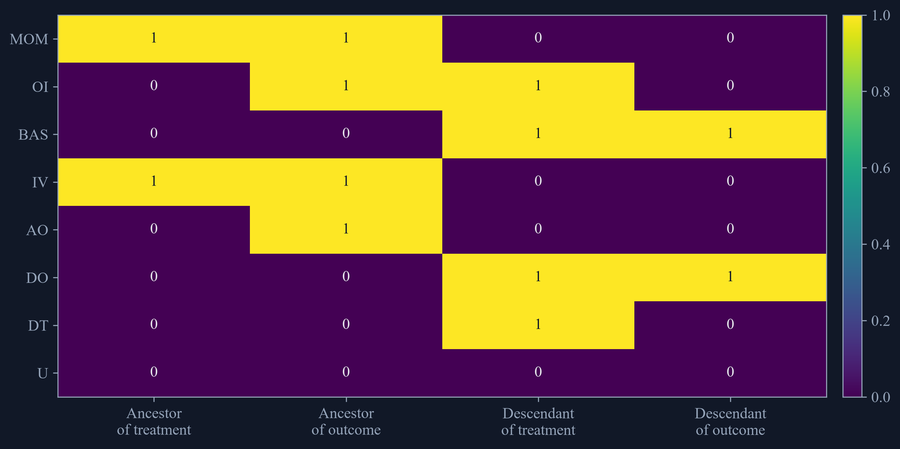

,Variable,Paths to treatment,Paths to outcome,Paths from treatment,Paths from outcome,Role
0,MOM,1,2,0,0,confounder
1,OI,0,1,1,0,mediator
2,BAS,0,0,2,1,collider
3,IV,1,1,0,0,instrument
4,AO,0,1,0,0,ancestor of outcome
5,DO,0,0,1,1,collider
6,DT,0,0,1,0,descendant of treatment
7,U,0,0,0,0,independent


In [2]:
ancestor_treatment = set(nx.ancestors(finance_graph, treatment))
ancestor_outcome = set(nx.ancestors(finance_graph, outcome))
descendant_treatment = set(nx.descendants(finance_graph, treatment))
descendant_outcome = set(nx.descendants(finance_graph, outcome))
reachability_rows = []
for variable in expected_roles:
    reachability_rows.append({"Variable": variable, "Ancestor of treatment": variable in ancestor_treatment, "Ancestor of outcome": variable in ancestor_outcome, "Descendant of treatment": variable in descendant_treatment, "Descendant of outcome": variable in descendant_outcome, "Role": classify_causal_role(finance_graph, treatment, outcome, variable).replace("_", " ")})
role_reachability = pd.DataFrame(reachability_rows)
save_table(role_reachability, "role_reachability", "Reachability facts used by the role classifier.", "tab:chapter23-role-reachability")
display(role_reachability)

reachability_values = role_reachability[["Ancestor of treatment", "Ancestor of outcome", "Descendant of treatment", "Descendant of outcome"]].astype(int).to_numpy()
figure, axis = plt.subplots(figsize=(9.5, 4.8))
image = axis.imshow(reachability_values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
axis.set_yticks(range(len(role_reachability)), role_reachability["Variable"])
axis.set_xticks(range(4), ["Ancestor\nof treatment", "Ancestor\nof outcome", "Descendant\nof treatment", "Descendant\nof outcome"])
for row in range(reachability_values.shape[0]):
    for column in range(reachability_values.shape[1]):
        axis.text(column, row, str(reachability_values[row, column]), ha="center", va="center", color=palette["text"] if reachability_values[row, column] == 0 else palette["background"])
figure.colorbar(image, ax=axis, fraction=0.03, pad=0.02)
figure.tight_layout()
save_figure(figure, "role_reachability_matrix")

witness_rows = []
for variable in expected_roles:
    directed_to_treatment = list(nx.all_simple_paths(finance_graph, variable, treatment)) if nx.has_path(finance_graph, variable, treatment) else []
    directed_to_outcome = list(nx.all_simple_paths(finance_graph, variable, outcome)) if nx.has_path(finance_graph, variable, outcome) else []
    from_treatment = list(nx.all_simple_paths(finance_graph, treatment, variable)) if nx.has_path(finance_graph, treatment, variable) else []
    from_outcome = list(nx.all_simple_paths(finance_graph, outcome, variable)) if nx.has_path(finance_graph, outcome, variable) else []
    witness_rows.append({"Variable": variable, "Paths to treatment": len(directed_to_treatment), "Paths to outcome": len(directed_to_outcome), "Paths from treatment": len(from_treatment), "Paths from outcome": len(from_outcome), "Role": classify_causal_role(finance_graph, treatment, outcome, variable).replace("_", " ")})
role_path_witnesses = pd.DataFrame(witness_rows)
save_table(role_path_witnesses, "role_path_witnesses", "Directed-path counts that witness each role.", "tab:chapter23-role-path-witnesses")
display(role_path_witnesses)

## A Known Finance System

The generated finance system follows the declared graph through one structural equation for each nonroot variable:

$$
\begin{aligned}
H&=0.65M+0.55I+\varepsilon_H,\\
O&=0.80H+\varepsilon_O,\\
P&=0.70O+0.55M+0.40A+\varepsilon_P,\\
B&=0.50O+0.60P+\varepsilon_B.
\end{aligned}
$$

Here, $H$ is HML, $M$ is momentum, $I$ is the instrument, $O$ is order imbalance, $P$ is price change, $A$ is an additional cause of price change, $B$ is the bid-ask spread, and each $\varepsilon$ is an independent standard-normal disturbance.

,Child,Parent,Coefficient
0,HML,Momentum,0.65
1,HML,Instrument,0.55
2,Order imbalance,HML,0.8
3,Price change,Order imbalance,0.7
4,Price change,Momentum,0.55
5,Price change,Outcome cause,0.4
6,Spread,Order imbalance,0.5
7,Spread,Price change,0.6


,Variable,Observations,Mean,Standard deviation
0,HML,50000,-0.00598,1.316369
1,OI,50000,0.002113,1.449452
2,PC,50000,0.009465,1.71005
3,MOM,50000,0.002024,0.994165
4,BAS,50000,0.01304,1.909617
5,IV,50000,-0.00134,0.999313
6,AO,50000,0.004726,1.004307
7,DO,50000,-0.002185,1.314328
8,DT,50000,0.000383,1.275381
9,U,50000,-0.000663,1.005118


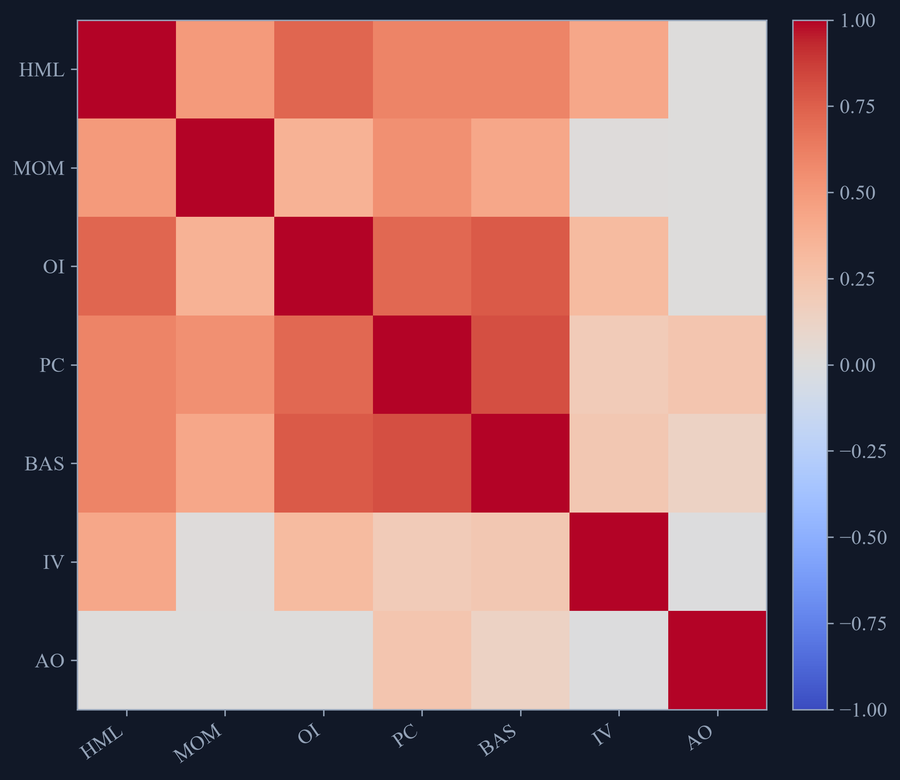

In [3]:
generated_size = 50000
rng = np.random.default_rng(2302)
momentum = rng.normal(size=generated_size)
instrument = rng.normal(size=generated_size)
outcome_cause = rng.normal(size=generated_size)
unrelated = rng.normal(size=generated_size)
hml = 0.65 * momentum + 0.55 * instrument + rng.normal(size=generated_size)
order_imbalance = 0.80 * hml + rng.normal(size=generated_size)
price_change = 0.70 * order_imbalance + 0.55 * momentum + 0.40 * outcome_cause + rng.normal(size=generated_size)
spread = 0.50 * order_imbalance + 0.60 * price_change + rng.normal(size=generated_size)
treatment_child = 0.60 * hml + rng.normal(size=generated_size)
outcome_child = 0.50 * price_change + rng.normal(size=generated_size)
generated_finance = pd.DataFrame({"HML": hml, "OI": order_imbalance, "PC": price_change, "MOM": momentum, "BAS": spread, "IV": instrument, "AO": outcome_cause, "DO": outcome_child, "DT": treatment_child, "U": unrelated})
finance_structural_parameters = pd.DataFrame([
    {"Child": "HML", "Parent": "Momentum", "Coefficient": 0.65},
    {"Child": "HML", "Parent": "Instrument", "Coefficient": 0.55},
    {"Child": "Order imbalance", "Parent": "HML", "Coefficient": 0.80},
    {"Child": "Price change", "Parent": "Order imbalance", "Coefficient": 0.70},
    {"Child": "Price change", "Parent": "Momentum", "Coefficient": 0.55},
    {"Child": "Price change", "Parent": "Outcome cause", "Coefficient": 0.40},
    {"Child": "Spread", "Parent": "Order imbalance", "Coefficient": 0.50},
    {"Child": "Spread", "Parent": "Price change", "Coefficient": 0.60},
])
generated_data_summary = pd.DataFrame({"Variable": generated_finance.columns, "Observations": len(generated_finance), "Mean": generated_finance.mean().to_numpy(), "Standard deviation": generated_finance.std().to_numpy()})
save_table(finance_structural_parameters, "finance_structural_parameters", "Coefficients in the known finance system.", "tab:chapter23-structural-parameters")
save_table(generated_data_summary, "generated_data_summary", "Generated observations from the declared finance graph.", "tab:chapter23-generated-data-summary")
display(finance_structural_parameters)
display(generated_data_summary)

core_variables = ["HML", "MOM", "OI", "PC", "BAS", "IV", "AO"]
core_correlation = generated_finance[core_variables].corr()
figure, axis = plt.subplots(figsize=(7.5, 6.2))
image = axis.imshow(core_correlation.to_numpy(dtype=float), vmin=-1, vmax=1, cmap="coolwarm")
axis.set_xticks(range(len(core_variables)), core_variables, rotation=35, ha="right")
axis.set_yticks(range(len(core_variables)), core_variables)
figure.colorbar(image, ax=axis, fraction=0.045, pad=0.03)
figure.tight_layout()
save_figure(figure, "finance_structural_correlations")

## Conditioning Changes the Question

A linear coefficient for the treatment is obtained by projecting the outcome on the treatment and the chosen control set:

$$
\widehat\beta_X(C)=e_X^{\mathsf T}(D_C^{\mathsf T}D_C)^{-1}D_C^{\mathsf T}Y.
$$

Here, $C$ is the control set, $D_C$ contains an intercept, the treatment $X$, and the controls in $C$, $Y$ is the outcome vector, $e_X$ selects the treatment coordinate, and $\widehat\beta_X(C)$ is the fitted treatment coefficient under that particular choice of controls.

,Specification,Controls,HML coefficient,Distance from total effect,R squared
0,No controls,None,0.771673,0.211673,0.352862
1,Confounder,MOM,0.561177,0.001177,0.433288
2,Confounder and outcome cause,"MOM, AO",0.559406,-0.000594,0.488608
3,Confounder and mediator,"MOM, OI",-0.004608,-0.564608,0.603739
4,Confounder and collider,"MOM, BAS",0.125718,-0.434282,0.707089
5,Confounder and unrelated,"MOM, U",0.561182,0.001182,0.43329


,Quantity,Value
0,Known indirect HML effect,0.56
1,Generated observations,50000
2,Disturbance variance,1
3,Confounder coefficient into HML,0.65
4,Confounder coefficient into price change,0.55


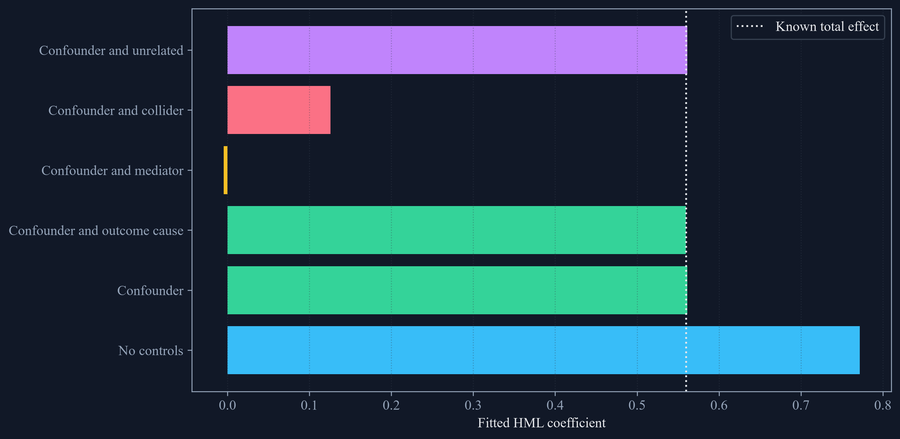

In [4]:
control_sets = {
    "No controls": [],
    "Confounder": ["MOM"],
    "Confounder and outcome cause": ["MOM", "AO"],
    "Confounder and mediator": ["MOM", "OI"],
    "Confounder and collider": ["MOM", "BAS"],
    "Confounder and unrelated": ["MOM", "U"],
}
adjustment_rows = []
total_effect = 0.80 * 0.70
for name, controls in control_sets.items():
    coefficient_value, r_squared = regression_summary(generated_finance, "PC", "HML", controls)
    adjustment_rows.append({"Specification": name, "Controls": ", ".join(controls) if controls else "None", "HML coefficient": coefficient_value, "Distance from total effect": coefficient_value - total_effect, "R squared": r_squared})
conditioning_comparison = pd.DataFrame(adjustment_rows)
role_regression_truth = pd.DataFrame({"Quantity": ["Known indirect HML effect", "Generated observations", "Disturbance variance", "Confounder coefficient into HML", "Confounder coefficient into price change"], "Value": [total_effect, generated_size, 1.0, 0.65, 0.55]})
save_table(conditioning_comparison, "conditioning_comparison", "Treatment coefficients under different conditioning choices.", "tab:chapter23-conditioning-comparison")
save_table(role_regression_truth, "role_regression_truth", "Known quantities in the finance system.", "tab:chapter23-role-regression-truth")
display(conditioning_comparison)
display(role_regression_truth)

figure, axis = plt.subplots(figsize=(10.5, 5.2))
bar_colors = [palette["cyan"], palette["green"], palette["green"], palette["amber"], palette["rose"], palette["violet"]]
axis.barh(conditioning_comparison["Specification"], conditioning_comparison["HML coefficient"], color=bar_colors)
axis.axvline(total_effect, color=palette["text"], linewidth=1.5, linestyle=":", label="Known total effect")
axis.set_xlabel("Fitted HML coefficient")
axis.legend()
axis.grid(axis="x", alpha=0.35)
figure.tight_layout()
save_figure(figure, "conditioning_coefficient_comparison")

## Instrument Role

In the declared graph, an instrument reaches the outcome only through the treatment and has no open path to the outcome after the treatment link is removed:

$$
I\rightsquigarrow X,\qquad I\rightsquigarrow Y\Rightarrow X\in\pi_{IY},\qquad I\perp_G Y\mid\operatorname{do}(X\leftarrow\varnothing).
$$

Here, $I$ is the proposed instrument, $X$ is the treatment, $Y$ is the outcome, $\pi_{IY}$ is any directed path from $I$ to $Y$, and $\operatorname{do}(X\leftarrow\varnothing)$ denotes removing arrows into the treatment for this graphical check.

,Condition,Result
0,Instrument reaches treatment,True
1,Every directed instrument-outcome path passes ...,True
2,No instrument-outcome path remains after remov...,True
3,Released classifier labels instrument,True


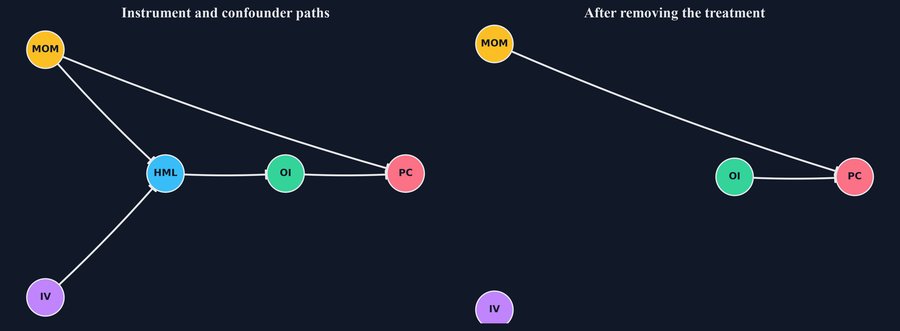

,Quantity,Value
0,Graph nodes,10
1,Directed edges,10
2,Classified variables,8
3,Matched role checks,8
4,Generated observations,50000
5,Conditioning choices,6
6,Instrument checks,4
7,Figures,5
8,Generated tables,10


In [5]:
directed_instrument_paths = list(nx.all_simple_paths(finance_graph, "IV", outcome))
graph_without_treatment = finance_graph.copy()
graph_without_treatment.remove_node(treatment)
instrument_conditions = pd.DataFrame([
    {"Condition": "Instrument reaches treatment", "Result": nx.has_path(finance_graph, "IV", treatment)},
    {"Condition": "Every directed instrument-outcome path passes through treatment", "Result": all(treatment in path for path in directed_instrument_paths)},
    {"Condition": "No instrument-outcome path remains after removing treatment", "Result": not nx.has_path(graph_without_treatment, "IV", outcome)},
    {"Condition": "Released classifier labels instrument", "Result": classify_causal_role(finance_graph, treatment, outcome, "IV") == "instrument"},
])
save_table(instrument_conditions, "instrument_conditions", "Graph checks for the proposed instrument.", "tab:chapter23-instrument-conditions")
display(instrument_conditions)

instrument_graph = finance_graph.subgraph(["IV", "MOM", "HML", "OI", "PC"]).copy()
instrument_positions = {"IV": (-2, -0.8), "MOM": (-2, 0.8), "HML": (-0.5, 0), "OI": (1, 0), "PC": (2.5, 0)}
instrument_colors = {"IV": palette["violet"], "MOM": palette["amber"], "HML": palette["cyan"], "OI": palette["green"], "PC": palette["rose"]}
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
draw_directed_graph(axes[0], instrument_graph, instrument_positions, "Instrument and confounder paths", instrument_colors)
removed_graph = instrument_graph.copy()
removed_graph.remove_node("HML")
removed_positions = {node: instrument_positions[node] for node in removed_graph.nodes}
draw_directed_graph(axes[1], removed_graph, removed_positions, "After removing the treatment", instrument_colors)
figure.tight_layout()
save_figure(figure, "instrument_role_paths")

role_section_summary = pd.DataFrame({"Quantity": ["Graph nodes", "Directed edges", "Classified variables", "Matched role checks", "Generated observations", "Conditioning choices", "Instrument checks", "Figures", "Generated tables"], "Value": [finance_graph.number_of_nodes(), finance_graph.number_of_edges(), len(role_classification), int(role_classification["Matched"].sum()), generated_size, len(conditioning_comparison), len(instrument_conditions), 5, 10]})
save_table(role_section_summary, "role_section_summary", "Section 23.2 numerical summary.", "tab:chapter23-role-section-summary")
display(role_section_summary)

## Tests

In [6]:
assert nx.is_directed_acyclic_graph(finance_graph)
assert role_classification["Matched"].all()
assert role_boolean_checks.loc[role_boolean_checks["Variable"] == "MOM", "Confounder"].iloc[0]
assert role_boolean_checks.loc[role_boolean_checks["Variable"] == "OI", "Mediator"].iloc[0]
assert role_boolean_checks.loc[role_boolean_checks["Variable"] == "BAS", "Collider"].iloc[0]
assert role_boolean_checks.loc[role_boolean_checks["Variable"] == "IV", "Instrument"].iloc[0]
assert len(role_reachability) == 8
assert len(role_path_witnesses) == 8
assert generated_finance.shape == (50000, 10)
assert np.isfinite(generated_finance.to_numpy()).all()
assert np.isclose(total_effect, 0.56)
adjusted_value = conditioning_comparison.loc[conditioning_comparison["Specification"] == "Confounder and outcome cause", "HML coefficient"].iloc[0]
mediator_value = conditioning_comparison.loc[conditioning_comparison["Specification"] == "Confounder and mediator", "HML coefficient"].iloc[0]
assert abs(adjusted_value - total_effect) < 0.03
assert abs(mediator_value) < 0.03
assert conditioning_comparison.loc[conditioning_comparison["Specification"] == "Confounder and collider", "Distance from total effect"].abs().iloc[0] > 0.05
assert instrument_conditions["Result"].all()
assert len(role_section_summary) == 9
for stem in ["finance_role_graph", "role_reachability_matrix", "finance_structural_correlations", "conditioning_coefficient_comparison", "instrument_role_paths"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["finance_graph_edges", "role_classification", "role_boolean_checks", "role_reachability", "role_path_witnesses", "finance_structural_parameters", "generated_data_summary", "conditioning_comparison", "instrument_conditions", "role_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()